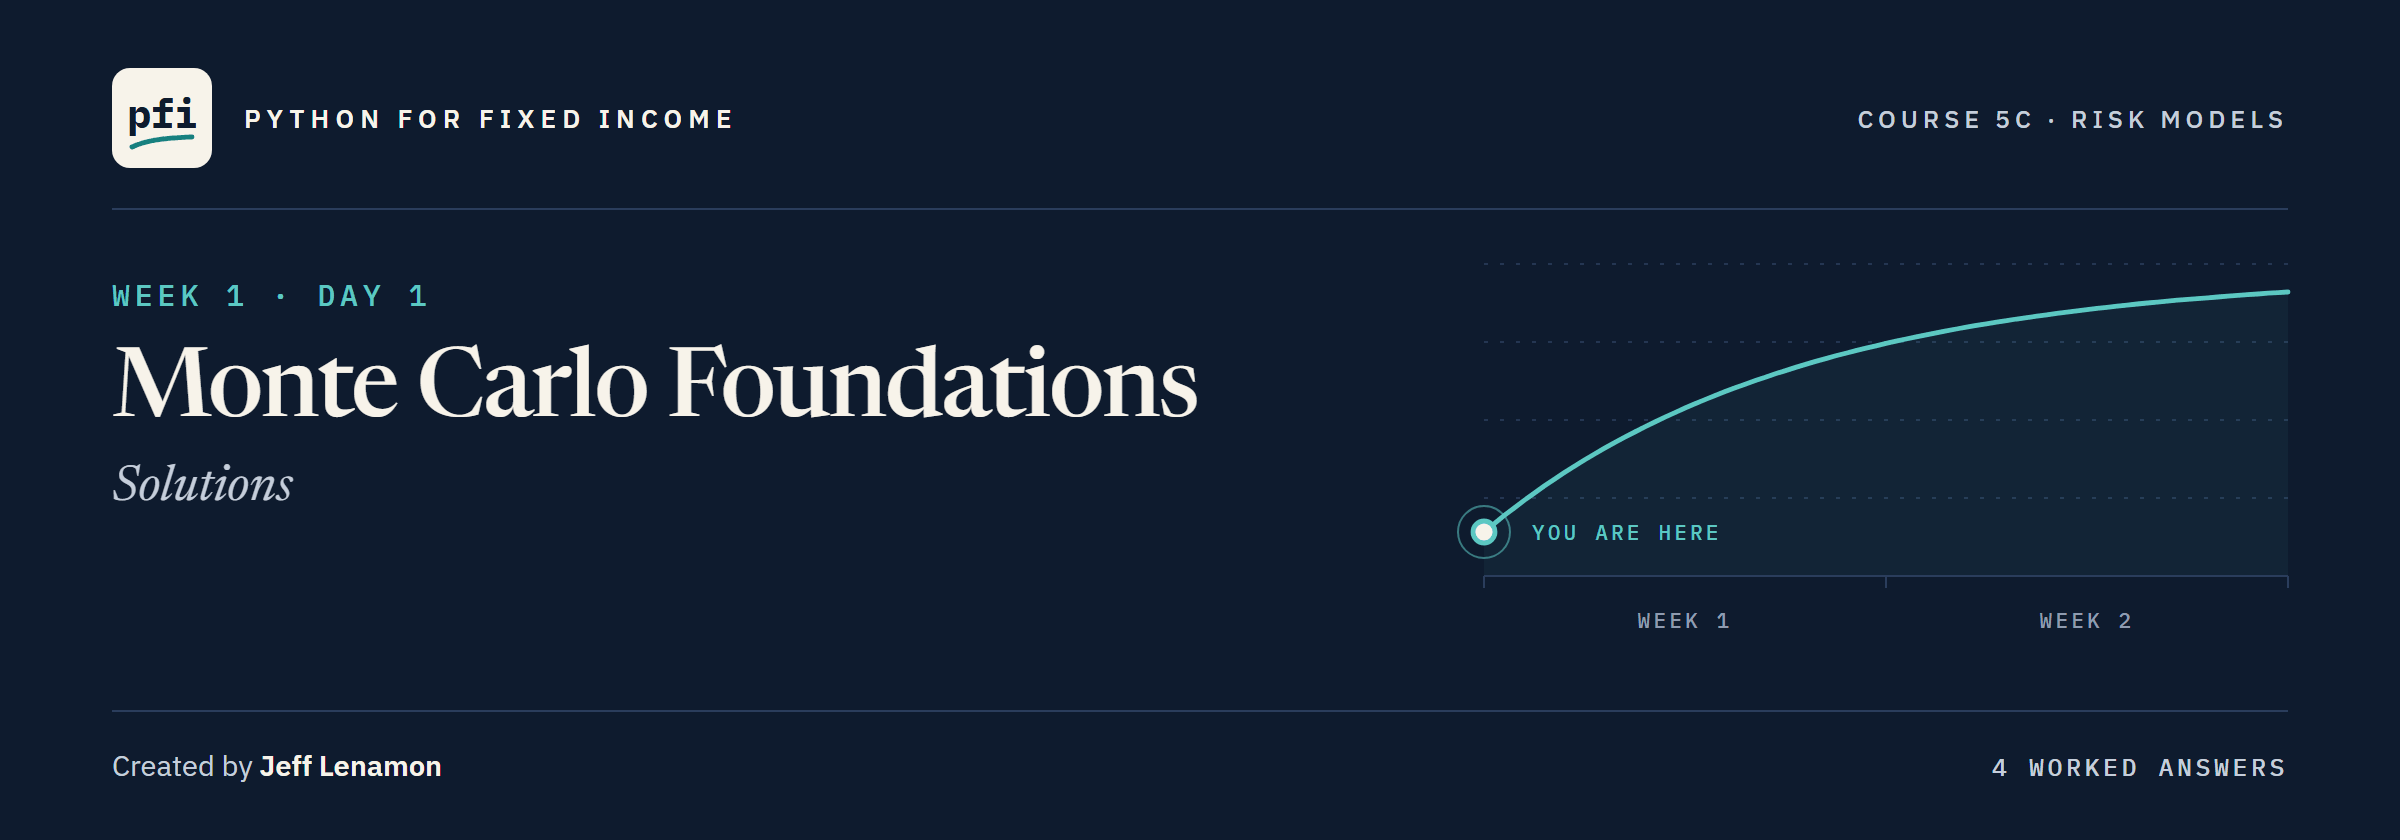

# Monte Carlo Foundations: Solutions

Week 1, Day 1. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day1/01_monte_carlo_foundations_solutions.ipynb)

# Problem Statement

## Business Context

A credit risk team holds a book of 200 bonds from 115 issuers, rated AAA to CCC, as of 2026-09-30.
Over the coming days it will simulate how a year's credit loss is spread across the book, where defaults move together and no formula gives the answer.
Before it trusts a simulation of the book, it tests the method on one bond, where the exact answer is known.
A simulated loss describes invented inputs, never a view on a bond.
Today reads only the book and fits nothing, so nothing is split.

## Objectives

Simulate one bond's credit loss year by year and set it beside PD x LGD x EAD.
Report a simulated mean with its standard error, and seed a generator and split it into independent streams.
Turn uniform draws into normal ones, and draw normal, Student's t, lognormal and beta inputs.
Check a simulated count of defaults against an exact formula, spend draws in antithetic pairs, work out the trials a stated precision needs, and test the 95 percent interval.

## Data Dictionary

`holdings.csv`, one row per bond (the columns used today):

1. `cusip`: the bond's identifier (invented)
2. `issuer`: the issuer's name (invented)
3. `rating`: the bond's rating, AAA to CCC
4. `oas`: the option-adjusted spread, bp
5. `spread_duration`: spread duration, years
6. `market_value`: the market value held, US$

The other 13 columns are not used today.
`ratings.csv` adds `bucket` (the letter grade, AAA to CCC) and `grade` (Investment Grade or High Yield).

Made in the notebook: `PD`, `LGD` and `EAD`, and `losses`, one simulated year's loss in US$ each, a loss written as a positive number.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data, and to round a count up
import math
import numpy as np
import pandas as pd

# the normal, Student's t and binomial curves
from scipy import stats

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Book and the Rating Scale

In [3]:
# the book of 200 synthetic bonds as of 2026-09-30, and the rating scale
book = pd.read_csv(DATA + "holdings.csv")
ratings = pd.read_csv(DATA + "ratings.csv")

# each bond's bucket and grade, matched on its rating
book = book.merge(ratings[["rating", "bucket", "grade"]], on="rating")
book.shape

(200, 21)

200 bonds: the file's 19 columns and the scale's two.

# Data Overview

## Checking the Book

In [4]:
# missing values, repeated CUSIPs, issuers, and the book's market value in US$ millions
print("Missing values:", book.isna().sum().sum(), "| repeated CUSIPs:", book["cusip"].duplicated().sum())
print("Issuers:", book["issuer"].nunique(), "| market value (US$ m):", round(book["market_value"].sum() / 1e6, 1))

Missing values: 0 | repeated CUSIPs: 0
Issuers: 115 | market value (US$ m): 490.8


Nothing is missing and each bond appears once.

## Bonds and Market Value by Bucket

In [5]:
# bonds and market value in each bucket, AAA first
order = ratings["bucket"].unique()
buckets = book.groupby("bucket").agg(bonds=("cusip", "size"), market_value_m=("market_value", "sum")).loc[order]
buckets["market_value_m"] = (buckets["market_value_m"] / 1e6).round(1)
buckets

,bonds,market_value_m
bucket,,
AAA,2,8.2
AA,8,13.0
A,56,148.5
BBB,62,151.2
BB,49,113.8
B,18,43.6
CCC,5,12.6


BBB and A hold most of the bonds; BB holds 49.

Only 23 bonds sit in B and CCC, the bottom of the scale.

## Picking Today's Bond

In [6]:
# the largest BB bond by market value carries today's lesson
bond = book[book["bucket"] == "BB"].sort_values("market_value").iloc[-1]
bond[["issuer", "cusip", "rating", "market_value", "oas", "spread_duration"]]

issuer             Lorvebran Paper
cusip                    99076YAC0
rating                          BB
market_value             5287462.5
oas                            229
spread_duration               6.24
Name: 103, dtype: object

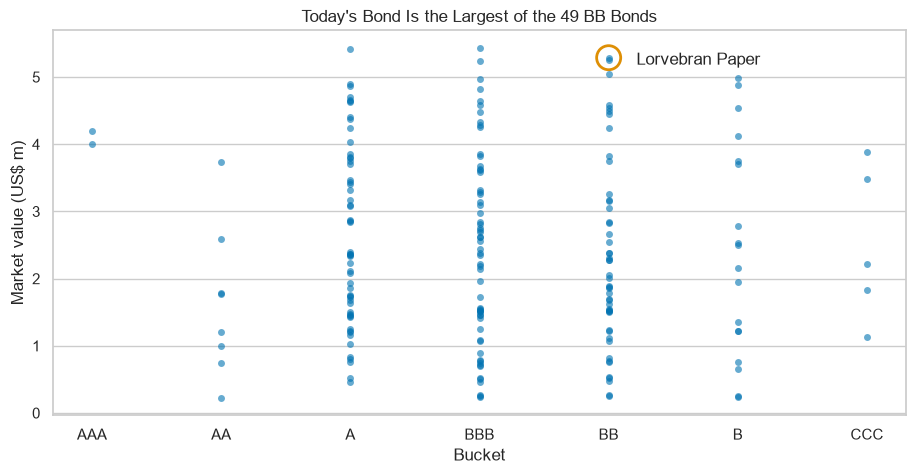

In [7]:
# every bond's market value in US$ millions by bucket, today's bond ringed (a circle with no fill and an orange edge)
plt.figure(figsize=(11, 5))
sns.stripplot(x=book["bucket"], y=book["market_value"] / 1e6, order=order, jitter=False, alpha=0.6)
plt.scatter(list(order).index("BB"), bond["market_value"] / 1e6, s=300, facecolors="none", edgecolors="C1", linewidths=2)
plt.annotate(bond["issuer"], (list(order).index("BB"), bond["market_value"] / 1e6), xytext=(20, -5), textcoords="offset points")
plt.xlabel("Bucket")
plt.ylabel("Market value (US$ m)")
plt.title("Today's Bond Is the Largest of the 49 BB Bonds")
plt.show()

Lorvebran Paper `99076YAC0`, at US$5,287,462.50, sits near the top of the whole book, with an OAS of 229 bp.

**One BB bond, the largest in its bucket, carries today's lesson.**

# One Bond's Loss in a Year

## Two Inputs Chosen for the Lesson

The **probability of default (PD)** is the chance the bond defaults within the year.
The **loss given default (LGD)** is the share of the exposure lost if it does.
The **exposure at default (EAD)** is what is at stake, here the bond's market value in US$.
The PD and LGD below are inputs chosen for the lesson, never an estimate for this or any issuer.

In [8]:
# a 2 percent chance of default in a year, and 60 percent of the market value lost if it happens
PD = 0.02
LGD = 0.60
EAD = bond["market_value"]
print("Loss if the bond defaults (US$):", round(LGD * EAD, 2))

Loss if the bond defaults (US$): 3172477.5


## The Exact Answer

The **expected loss** is PD x LGD x EAD, the average loss over many years.
In this course a loss is a positive number of US$.

In [9]:
# the expected loss in US$
EL = PD * LGD * EAD
print("Expected loss (US$):", round(EL, 2))

Expected loss (US$): 63449.55


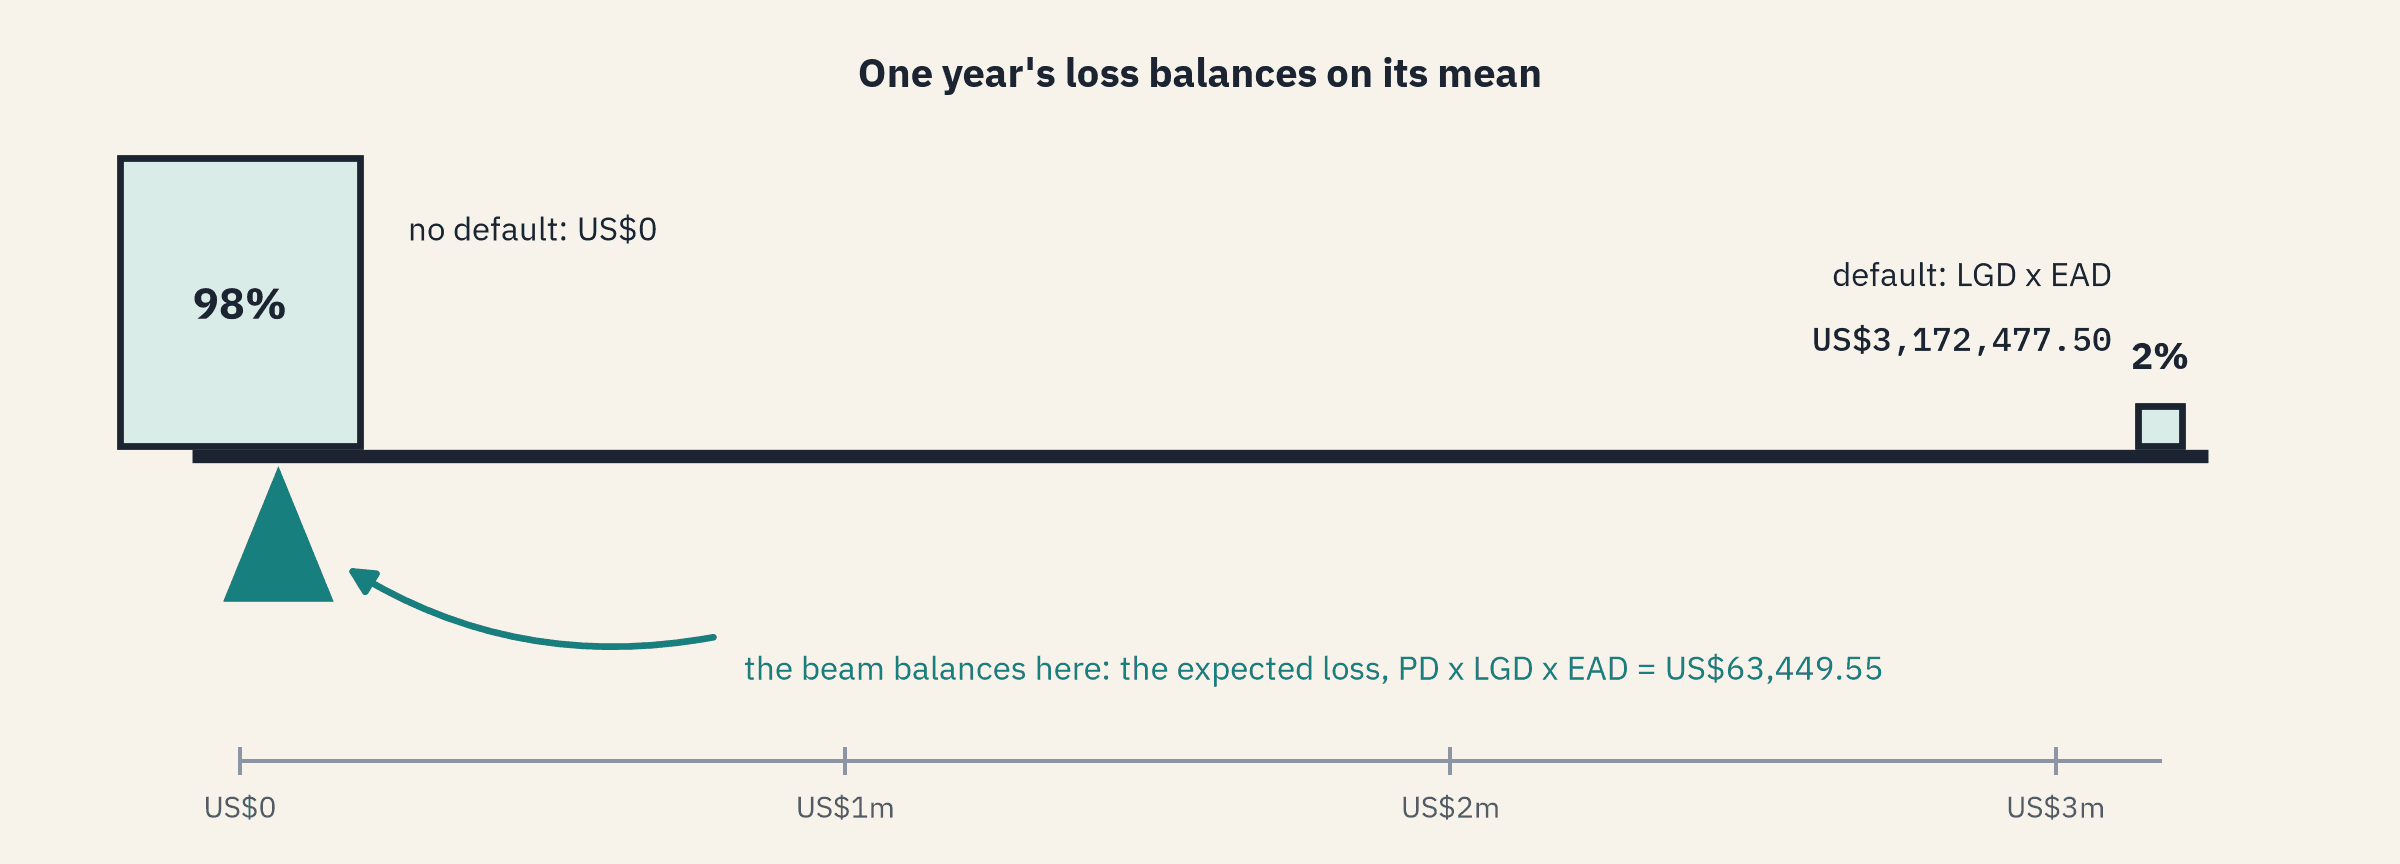

A year's loss is US$0 or US$3,172,477.50, never the US$63,449.55 it averages.

**Predict 1**

A year's loss is US$0 in 98 years of 100 and US$3,172,477.50 in the other 2, and averages US$63,449.55.

Q. Its standard deviation is how many times that mean? Write down a number.

## How Spread Out One Year Is

A loss that takes one amount with chance PD and is zero otherwise has a standard deviation of sqrt(PD x (1 - PD)) x LGD x EAD.

In [10]:
# the standard deviation of one year's loss in US$, and as a multiple of the mean
sd = np.sqrt(PD * (1 - PD)) * LGD * EAD
print("Standard deviation (US$):", round(sd, 2), "| times the mean:", round(sd / EL, 2))

Standard deviation (US$): 444146.85 | times the mean: 7.0


The standard deviation is seven times the mean, because sqrt(0.98 / 0.02) is 7.

A rare, large loss spreads far wider than its mean, so an average of draws needs many of them to settle.

## Ten Simulated Years

**Monte Carlo** answers a question by drawing at random many times and averaging; each draw is a **trial**, here one simulated year.
`rng.random(n)` (Course 5's Day 13) draws n numbers spread evenly between 0 and 1, so a draw lands below 0.02 two times in a hundred.
A year defaults when its draw is below PD.

In [11]:
# a generator fixed by the seed (Course 1), and ten draws between 0 and 1
rng = np.random.default_rng(SEED)
draws = rng.random(10)
print(draws.round(3))
print("Defaults in ten years:", (draws < PD).sum())

[0.774 0.439 0.859 0.697 0.094 0.976 0.761 0.786 0.128 0.45 ]
Defaults in ten years: 0


## 100,000 Simulated Years

In [12]:
# 100,000 years from a fresh generator: a year's loss is LGD x EAD when its draw is below PD, else US$0
rng = np.random.default_rng(SEED)
draws = rng.random(100_000)
losses = np.where(draws < PD, LGD * EAD, 0.0)
print("Defaults:", (losses > 0).sum(), "| mean loss (US$):", round(losses.mean(), 2))
print("Short of the exact answer by (US$):", round(EL - losses.mean(), 2))

Defaults: 1991 | mean loss (US$): 63164.03
Short of the exact answer by (US$): 285.52


Defaults in the first 1,000 years: 20 | the first in year 52


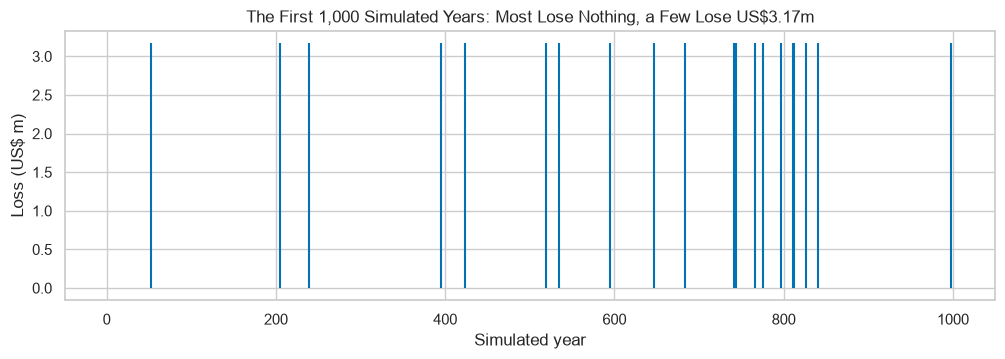

In [13]:
# the first 1,000 simulated years: a stem for each year that defaulted
print("Defaults in the first 1,000 years:", (losses[:1000] > 0).sum(), "| the first in year", np.argmax(losses > 0) + 1)
plt.figure(figsize=(12, 3.5))
plt.vlines(np.arange(1, 1001), 0, losses[:1000] / 1e6, color="C0")
plt.xlabel("Simulated year")
plt.ylabel("Loss (US$ m)")
plt.title("The First 1,000 Simulated Years: Most Lose Nothing, a Few Lose US$3.17m")
plt.show()

Twenty of the first 1,000 years default and the rest lose nothing.

Over 100,000 years the mean lands US$285.52 short of PD x LGD x EAD.

**100,000 draws land within US$286 of the exact answer, and the next section measures how close they should land.**

> STORY: Nicholas Metropolis wrote the method's history for Los Alamos Science in 1987.
> Stan Ulam attended a review of calculations run on the ENIAC in the spring of 1946.
> He knew statistical sampling had fallen out of use because its calculations were long and tedious, and with the new machine it occurred to him that it should be revived.
> On March 11, 1947 John von Neumann sent Robert Richtmyer a handwritten letter outlining a statistical approach to neutron diffusion.
> Metropolis wrote that he suggested the name, "not unrelated to the fact that Stan had an uncle who would borrow money from relatives because he 'just had to go to Monte Carlo.'"
> Source: N. Metropolis, "The Beginning of the Monte Carlo Method", Los Alamos Science, Special Issue 1987, pages 125 to 130, https://mcnpx.lanl.gov/pdf_files/Article_1987_LAS_Metropolis_125--130.pdf

# How Far Off the Mean Can Be

## The Standard Error of a Simulated Mean

The **standard error** of a mean (Course 4's Day 3) is the standard deviation of the draws over the square root of their number, `x.std(ddof=1) / np.sqrt(len(x))`.
It says how far a simulated mean typically lands from the exact answer.

In [14]:
# the first 1,000 years: their mean loss and its standard error, in US$
first = losses[:1000]
print("Mean (US$):", round(first.mean(), 2), "| standard error (US$):", round(first.std(ddof=1) / np.sqrt(len(first)), 2))

Mean (US$): 63449.55 | standard error (US$): 14052.18


The first 1,000 years land on the exact answer by luck: 20 defaults in 1,000 is exactly 2 percent.

**Predict 2**

1,000 years give a standard error of US$14,052.

Q. What standard error do 100,000 years give? Write down a number in US$.

## A Hundred Times the Years

In [15]:
# the mean and its standard error after 100, 1,000, 10,000 and 100,000 years, and the gap in standard errors
rows = []
for n in [100, 1_000, 10_000, 100_000]:
    x = losses[:n]
    rows.append({"years": n, "mean (US$)": x.mean(), "standard error (US$)": x.std(ddof=1) / np.sqrt(n)})
table = pd.DataFrame(rows)
table["gap in standard errors"] = (table["mean (US$)"] - EL) / table["standard error (US$)"]
table.round(2)

,years,mean (US$),standard error (US$),gap in standard errors
0,100,31724.78,31724.78,-1.00
1,1000,63449.55,14052.18,0.00
2,10000,59325.33,4297.76,-0.96
3,100000,63164.03,1401.42,-0.20


### Interpretation of the Standard Error

From 1,000 to 100,000 years the standard error falls from US$14,052.18 to US$1,401.42, a tenth.

A hundred times the trials buys ten times the precision: the standard error shrinks with one over the square root of the trials.

Every mean sits within 1.96 standard errors of the exact answer.

The **law of large numbers** says the mean of more and more draws settles on the exact answer; the standard error says how fast.

## Twenty Runs From One Seed

`np.random.default_rng(SEED).spawn(20)` makes twenty **child generators** from one seed: twenty streams that never overlap, all fixed by SEED.
A running mean (Course 5's Day 1) is `np.cumsum(x) / np.arange(1, len(x) + 1)`.

In [16]:
# twenty runs of 100,000 years, each from its own child of SEED, kept as running means in US$
running = []
for child in np.random.default_rng(SEED).spawn(20):
    run = np.where(child.random(100_000) < PD, LGD * EAD, 0.0)
    running.append(np.cumsum(run) / np.arange(1, 100_001))
running = np.array(running)

In [17]:
# the exact band, EL plus or minus 1.96 standard errors, and the runs inside it after 1,000 and 100,000 years
for n in [1_000, 100_000]:
    band = 1.96 * sd / np.sqrt(n)
    inside = (np.abs(running[:, n - 1] - EL) <= band).sum()
    print(f"After {n:,} years: means from {running[:, n - 1].min():,.0f} to {running[:, n - 1].max():,.0f} US$,",
          f"{inside} of 20 inside plus or minus {band:,.2f}")

After 1,000 years: means from 44,415 to 92,002 US$, 19 of 20 inside plus or minus 27,528.51
After 100,000 years: means from 62,022 to 65,956 US$, 20 of 20 inside plus or minus 2,752.85


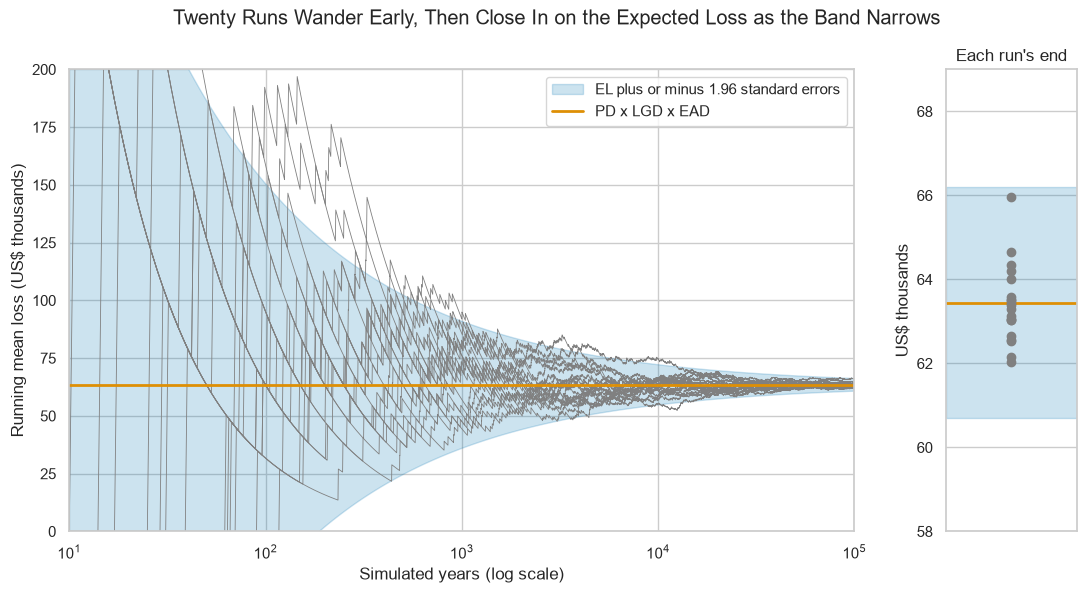

In [18]:
# the twenty running means inside the band on a log axis of years; at the right, where each run ended, zoomed in
years = np.arange(1, 100_001)
band = 1.96 * sd / np.sqrt(years)
fig, (ax, end) = plt.subplots(1, 2, figsize=(13, 6), width_ratios=[6, 1])
ax.fill_between(years, (EL - band) / 1e3, (EL + band) / 1e3, color="C0", alpha=0.2, label="EL plus or minus 1.96 standard errors")
ax.plot(years, running.T / 1e3, color="gray", linewidth=0.6)
ax.axhline(EL / 1e3, color="C1", linewidth=2, label="PD x LGD x EAD")
ax.set(xscale="log", xlim=(10, 100_000), ylim=(0, 200), xlabel="Simulated years (log scale)", ylabel="Running mean loss (US$ thousands)")
ax.legend(loc="upper right")
end.axhspan((EL - band[-1]) / 1e3, (EL + band[-1]) / 1e3, color="C0", alpha=0.2)
end.axhline(EL / 1e3, color="C1", linewidth=2)
end.scatter(np.zeros(20), running[:, -1] / 1e3, color="gray", zorder=3)
end.set(xticks=[], ylim=(58, 69), ylabel="US$ thousands", title="Each run's end")
fig.suptitle("Twenty Runs Wander Early, Then Close In on the Expected Loss as the Band Narrows")
plt.show()

At 1,000 years the twenty means still run from US$44,415 to US$92,002, and 19 of 20 sit inside the band.

At 100,000 years all twenty sit inside US$2,752.85 either side of US$63,449.55.

**From here on, a simulated loss is printed with its standard error.**

# Seeds and Streams

## The Same Seed, the Same Draws

In [19]:
# two generators from the same seed draw the same numbers, as the ten years and the 100,000 did
print(np.random.default_rng(SEED).random(3))
print(np.random.default_rng(SEED).random(3))

[0.77395605 0.43887844 0.85859792]
[0.77395605 0.43887844 0.85859792]


The ten simulated years above were the first ten of the 100,000.

## Why the Course Never Uses the Global Seed

Course 1's More Visualization notebook seeded numpy's **global state** with `np.random.seed()`: one stream that every cell draws from.
`np.random.rand(n)` draws n numbers between 0 and 1 from that one stream.

In [20]:
# a demonstration of the old global seed: one extra draw anywhere shifts every later number
np.random.seed(SEED)
print(np.random.rand(3))
np.random.seed(SEED)
extra = np.random.rand()
print(np.random.rand(3))

[0.37454012 0.95071431 0.73199394]
[0.95071431 0.73199394 0.59865848]


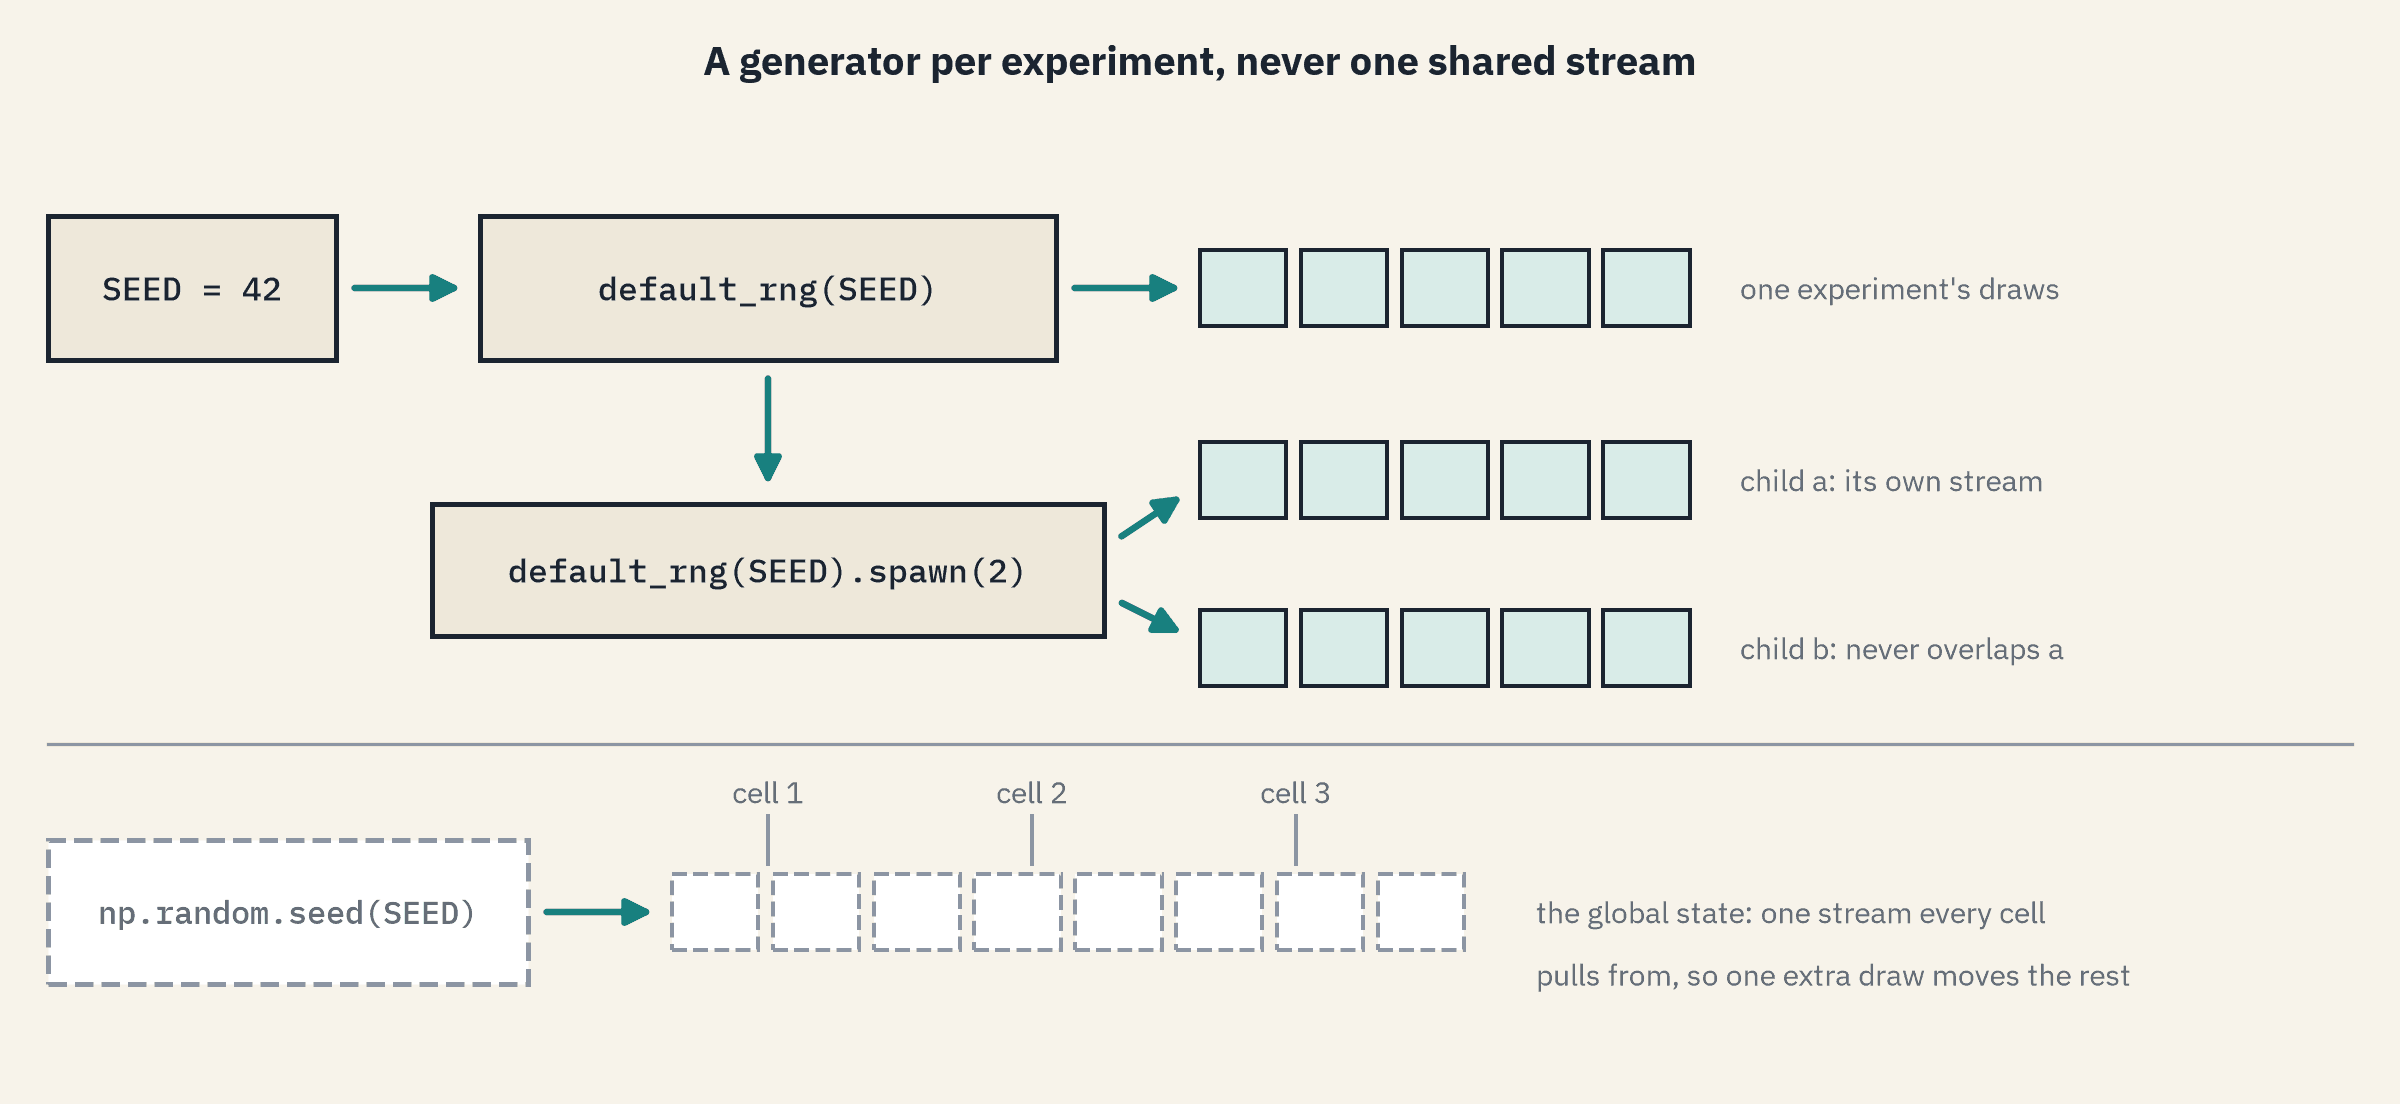

One extra draw, made anywhere, moves the next three along by one.

A generator belongs to one experiment, so draws elsewhere never touch it.

## Spawned Children

In [21]:
# two children of SEED: independent streams for two experiments side by side
child_a, child_b = np.random.default_rng(SEED).spawn(2)
print(child_a.random(3))
print(child_b.random(3))

[0.91674416 0.91098667 0.8765925 ]
[0.46749078 0.0464489  0.59551001]


**One generator per experiment, made from SEED; experiments side by side get spawned children.**

# Drawing Risk Inputs

## From a Uniform Draw to a Normal One

The **inverse transform** turns a uniform draw into any distribution: read the draw as a share and find the value with that share of the curve below it.
`stats.norm.cdf(x)` gives the share of the normal curve below x, the complement of Course 5B's Day 7 `stats.norm.sf`.
`stats.norm.ppf(u)` goes back from a share to its value, as Course 5B's Day 4 `stats.chi2.ppf` did.

In [22]:
# the 100,000 uniform draws above, turned into normal draws
normal_draws = stats.norm.ppf(draws)
print("Mean:", normal_draws.mean().round(4), "| standard deviation:", normal_draws.std().round(4))

Mean: 0.0015 | standard deviation: 1.0007


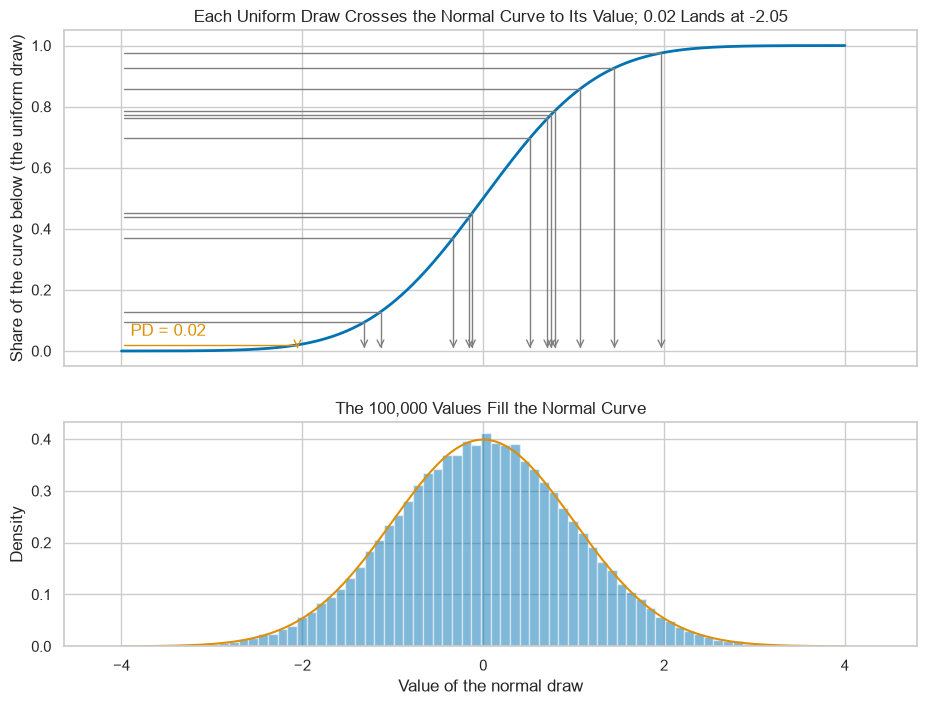

In [23]:
# twelve draws read on the share axis, across the normal curve and down to their value; PD's arrow in orange
# connectionstyle "angle" bends each arrow once, at a right angle, where it meets the curve
x = np.linspace(-4, 4, 400)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, height_ratios=[3, 2])
top.plot(x, stats.norm.cdf(x), color="C0", linewidth=2)
for u in list(draws[:12]) + [PD]:
    colour = "C1" if u == PD else "gray"
    top.annotate("", xy=(stats.norm.ppf(u), 0), xytext=(-4, u), arrowprops={"arrowstyle": "->", "color": colour, "connectionstyle": "angle,angleA=0,angleB=90"})
top.text(-3.9, 0.05, "PD = 0.02", color="C1")
bottom.hist(normal_draws, bins=80, density=True, alpha=0.5)
bottom.plot(x, stats.norm.pdf(x), color="C1")
top.set(ylabel="Share of the curve below (the uniform draw)", title="Each Uniform Draw Crosses the Normal Curve to Its Value; 0.02 Lands at -2.05")
bottom.set(xlabel="Value of the normal draw", ylabel="Density", title="The 100,000 Values Fill the Normal Curve")
plt.show()

The normal draws have mean 0.0015 and standard deviation 1.0007, close to the curve's 0 and 1.

### The Same Defaults From Normal Draws

In [24]:
# the normal value with 2 percent of the curve below it, and the years whose normal draw falls below it
cutoff = stats.norm.ppf(PD)
print("Value at 2 percent:", cutoff.round(4), "| years below it:", (normal_draws < cutoff).sum())
print("The same years as draws below PD:", np.array_equal(normal_draws < cutoff, draws < PD))

Value at 2 percent: -2.0537 | years below it: 1991
The same years as draws below PD: True


A normal draw below -2.0537 picks exactly the 1,991 default years; Day 3 builds its defaults on this line.

## Four Distributions, One Setting Each

A risk model reaches for four kinds of draw:

* `rng.standard_normal(n)`: the normal (Course 1).
* `rng.standard_t(df, n)`: Student's t with `df` degrees of freedom (Course 5B's Day 7), divided by sqrt(df / (df - 2)) so its standard deviation is 1.
* `rng.lognormal(mean=, sigma=, size=)`: a positive draw whose log is normal, for a move that multiplies. `mean` is the log's mean, and at -sigma squared over 2 the draws average 1.
* `rng.beta(a, b, n)`: a share between 0 and 1 with mean a / (a + b), for an LGD.

In [25]:
# 100,000 draws at each setting from one generator
rng = np.random.default_rng(SEED)
draws_by_setting = {"normal": rng.standard_normal(100_000)}
for df in [30, 5, 3]:
    draws_by_setting[f"t, df {df}"] = rng.standard_t(df, 100_000) / np.sqrt(df / (df - 2))
for s in [0.2, 0.4, 0.8]:
    draws_by_setting[f"lognormal, sigma {s}"] = rng.lognormal(mean=-s ** 2 / 2, sigma=s, size=100_000)
for a, b in [(3, 2), (6, 4), (12, 8)]:
    draws_by_setting[f"beta ({a}, {b})"] = rng.beta(a, b, 100_000)

In [26]:
# each setting's mean, median and standard deviation
summary = pd.DataFrame(draws_by_setting).agg(["mean", "median", "std"]).T
summary.round(3)

,mean,median,std
normal,-0.004,-0.009,1.004
"t, df 30",0.001,0.003,0.998
"t, df 5",-0.005,-0.002,1.001
"t, df 3",0.003,0.002,1.010
"lognormal, sigma 0.2",1.000,0.980,0.202
"lognormal, sigma 0.4",1.000,0.923,0.417
"lognormal, sigma 0.8",1.003,0.730,0.941
"beta (3, 2)",0.600,0.614,0.200
"beta (6, 4)",0.600,0.607,0.147
"beta (12, 8)",0.600,0.603,0.107


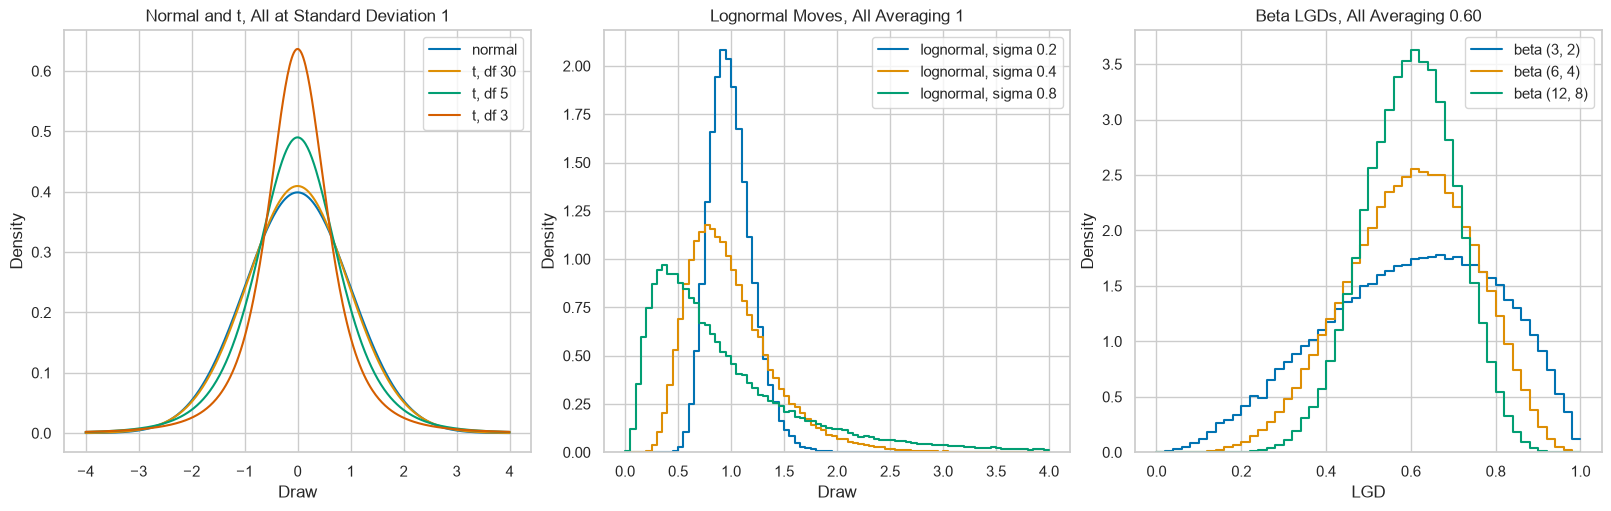

In [27]:
# the four families side by side: exact curves for the normal and t, the draws for the lognormal and beta
fig, axes = plt.subplots(1, 3, figsize=(16, 5), layout="constrained")
x = np.linspace(-4, 4, 400)
axes[0].plot(x, stats.norm.pdf(x), label="normal")
for df in [30, 5, 3]:
    axes[0].plot(x, stats.t.pdf(x, df, scale=np.sqrt((df - 2) / df)), label=f"t, df {df}")
for ax, family, edges in [(axes[1], "lognormal", np.linspace(0, 4, 81)), (axes[2], "beta", np.linspace(0, 1, 51))]:
    for name in [n for n in draws_by_setting if n.startswith(family)]:
        sns.histplot(draws_by_setting[name], stat="density", element="step", fill=False, bins=edges, ax=ax, label=name)
axes[0].set(title="Normal and t, All at Standard Deviation 1", xlabel="Draw", ylabel="Density")
axes[1].set(title="Lognormal Moves, All Averaging 1", xlabel="Draw")
axes[2].set(title="Beta LGDs, All Averaging 0.60", xlabel="LGD")
for ax in axes:
    ax.legend()
plt.show()

The normal and the t's share a mean of 0 and a standard deviation of 1; the t's are taller in the middle.

The lognormal's median falls from 0.98 to 0.73 as sigma rises from 0.2 to 0.8, while its mean stays at 1.

The three betas share a mean of 0.60, and their standard deviation falls from 0.200 to 0.107 as a and b grow.

**Predict 3**

The normal and Student's t with 3 degrees of freedom are both scaled to a standard deviation of 1.

Q. How many times the normal's share of draws does the t put beyond 3 on either side? Write down a number.

## Tails at the Same Standard Deviation

The share of draws beyond k on either side is an **exceedance**.
`2 * stats.t.sf(k, df, scale=...)` gives the t's exactly, as `2 * stats.norm.sf(k)` gives the normal's.

In [28]:
# a million draws each, scaled to a standard deviation of 1
rng = np.random.default_rng(SEED)
million = {"normal": rng.standard_normal(1_000_000)}
for df in [30, 5, 3]:
    million[f"t, df {df}"] = rng.standard_t(df, 1_000_000) / np.sqrt(df / (df - 2))

In [29]:
# the share of draws beyond k on either side, for k from 1 to 6
k = np.arange(1, 7)
exceed = pd.DataFrame(index=k)
for name, x in million.items():
    exceed[name] = [np.mean(np.abs(x) > j) for j in k]
exceed

,normal,"t, df 30","t, df 5","t, df 3"
1,0.317110,0.307928,0.252744,0.181419
2,0.045678,0.046726,0.049144,0.040168
3,0.002763,0.004048,0.011680,0.013657
4,0.000080,0.000248,0.003564,0.006017
5,0.000001,0.000019,0.001368,0.003187
6,0.000000,0.000002,0.000624,0.001879


In [30]:
# beyond 3: the t with df 3 against the normal, simulated and exact
exact = 2 * stats.t.sf(3, 3, scale=np.sqrt(1 / 3)) / (2 * stats.norm.sf(3))
print("Simulated:", round(exceed.loc[3, "t, df 3"] / exceed.loc[3, "normal"], 2), "times | exact:", round(exact, 2), "times")

Simulated: 4.94 times | exact: 5.13 times


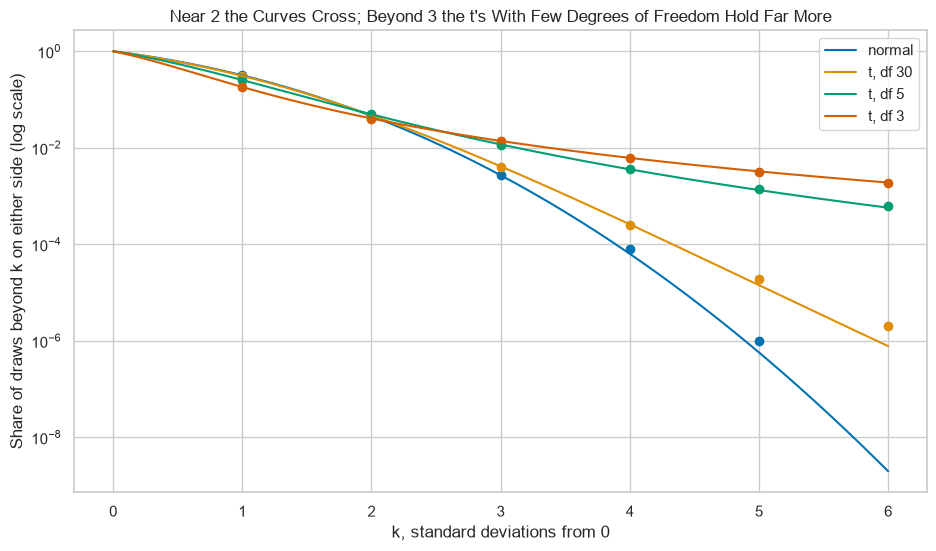

In [31]:
# exceedance curves on a log axis: exact lines from sf, simulated dots
k_fine = np.linspace(0, 6, 200)
plt.figure(figsize=(11, 6))
plt.plot(k_fine, 2 * stats.norm.sf(k_fine), color="C0", label="normal")
plt.scatter(k, exceed["normal"], color="C0")
for colour, df in zip(["C1", "C2", "C3"], [30, 5, 3]):
    plt.plot(k_fine, 2 * stats.t.sf(k_fine, df, scale=np.sqrt((df - 2) / df)), color=colour, label=f"t, df {df}")
    plt.scatter(k, exceed[f"t, df {df}"], color=colour)
plt.yscale("log")
plt.xlabel("k, standard deviations from 0")
plt.ylabel("Share of draws beyond k on either side (log scale)")
plt.title("Near 2 the Curves Cross; Beyond 3 the t's With Few Degrees of Freedom Hold Far More")
plt.legend()
plt.show()

Beyond 2 the t with 3 degrees of freedom holds a little less than the normal, 0.040 against 0.046.

Beyond 5 it holds 0.0032 of its draws, where the normal holds one in a million.

**Two inputs with the same standard deviation can carry very different tails; Day 2 meets this in the book's daily moves.**

# Defaults Among Fifty Bonds

## Fifty Independent Bonds, Simulated

Fifty invented bonds, each with today's PD of 2 percent, are **independent** when one bond's default changes nothing about another's.
`rng.random((100_000, 50))` draws a table, a row for each year and a column for each bond, and `.sum(axis=1)` totals each row (Course 1).

In [32]:
# 100,000 years of 50 independent bonds: how many default in each year
rng = np.random.default_rng(SEED)
counts = (rng.random((100_000, 50)) < PD).sum(axis=1)
print("Average defaults a year:", counts.mean(), "| most in one year:", counts.max())

Average defaults a year: 0.9979 | most in one year: 7


**Predict 4**

Fifty bonds at 2 percent average one default a year.

Q. In what share of years does none of the fifty default? Write down a percent.

## The Exact Answer: the Binomial

The count of defaults among n independent bonds follows the binomial (Course 5's Day 2).
`stats.binom.pmf(k, n, p)` is the chance of exactly k, and `stats.binom.sf(k, n, p)` the chance of more than k.

In [33]:
# the simulated share of years with each count, beside the binomial's exact chance
k = np.arange(0, 8)
fifty = pd.DataFrame({"simulated": [np.mean(counts == j) for j in k], "exact": stats.binom.pmf(k, 50, PD)}, index=k)
fifty.round(4)

,simulated,exact
0,0.3638,0.3642
1,0.3716,0.3716
2,0.1873,0.1858
3,0.0606,0.0607
4,0.0138,0.0145
5,0.0026,0.0027
6,0.0003,0.0004
7,0.0000,0.0001


In [34]:
# four or more defaults in a year, exact and simulated
print("Exact:", stats.binom.sf(3, 50, PD).round(4), "| simulated:", np.mean(counts >= 4).round(4))

Exact: 0.0178 | simulated: 0.0167


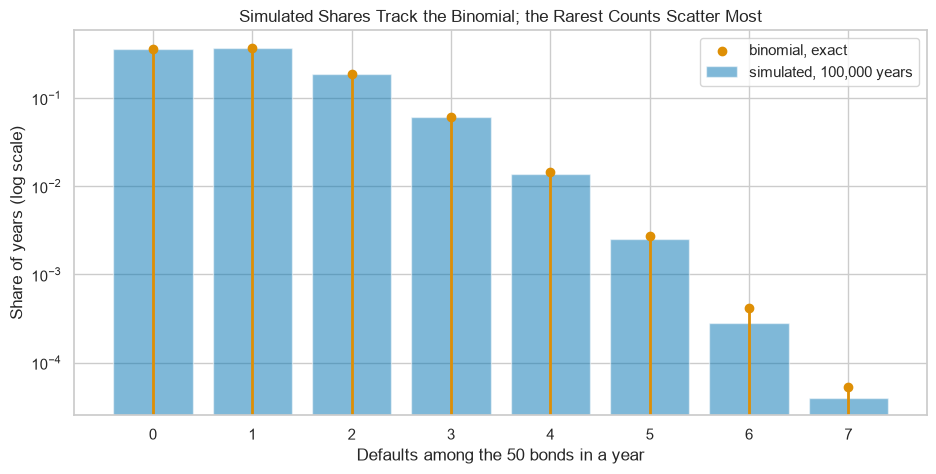

In [35]:
# simulated shares as bars against the binomial's exact chance as stems, on a log axis
plt.figure(figsize=(11, 5))
plt.bar(k, fifty["simulated"], color="C0", alpha=0.5, label="simulated, 100,000 years")
plt.vlines(k, 0, fifty["exact"], color="C1", linewidth=2)
plt.scatter(k, fifty["exact"], color="C1", zorder=3, label="binomial, exact")
plt.yscale("log")
plt.xlabel("Defaults among the 50 bonds in a year")
plt.ylabel("Share of years (log scale)")
plt.title("Simulated Shares Track the Binomial; the Rarest Counts Scatter Most")
plt.legend()
plt.show()

Up to three defaults the simulated share sits within 0.002 of the binomial's.

Six and seven defaults, seen in a few dozen years or fewer, fall a little short, 0.0003 against 0.0004 at six: the scatter a count that rare carries.

**Where a formula exists the simulation must land on it; once defaults move together (Day 3), only the simulation is left.**

# Antithetic Pairs

## A Draw and Its Mirror

**Antithetic variates** spend draws in pairs: draw z, and use its **mirror** -z too.
The two halves of a pair are not independent, so the standard error comes from the **pair means**, never from the single values.

Two payoffs of a normal draw z for today's bond:

* A year's spread move of OAS x (exp(sigma z - sigma squared / 2) - 1) bp, a lognormal move with a mean of 0 bp; its spread loss is spread duration x EAD x move / 10,000, positive when the spread widens, and its true mean is US$0.
* The size of a rate move, |10 z| bp, the same at z and -z.

In [36]:
# sigma of the spread move: an input chosen for the lesson
SIGMA = 0.40

# a year's spread loss in US$ (a widening is a loss), and the size of a rate move in bp
def spread_loss(z):
    move_bp = bond["oas"] * (np.exp(SIGMA * z - SIGMA ** 2 / 2) - 1)
    return bond["spread_duration"] * EAD * move_bp / 10_000

def move_size(z):
    return np.abs(10 * z)

## The Same 20,000 Draws Spent Two Ways

In [37]:
# two children of SEED: 20,000 plain draws, and 10,000 draws to spend with their mirrors
rng_plain, rng_pairs = np.random.default_rng(SEED).spawn(2)
plain = rng_plain.standard_normal(20_000)
half = rng_pairs.standard_normal(10_000)

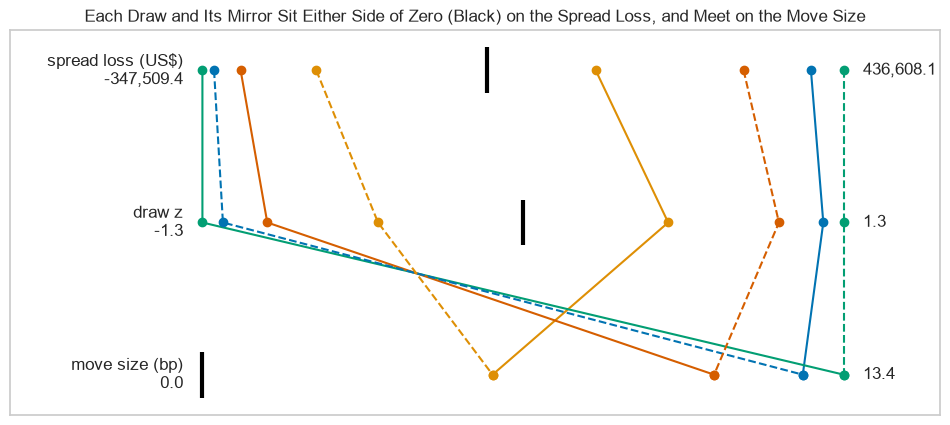

In [38]:
# four draws (solid) and their mirrors (dashed), joined across three number lines, each scaled to its own range
z = np.concatenate([half[:4], -half[:4]])
lines = {"spread loss (US$)": spread_loss(z), "draw z": z, "move size (bp)": move_size(z)}
fig, ax = plt.subplots(figsize=(12, 5))
for row, (name, values) in enumerate(lines.items()):
    low, high = min(values.min(), 0), values.max()
    ax.text(-0.03, 2 - row, f"{name}\n{low:,.1f}", ha="right", va="center")
    ax.text(1.03, 2 - row, f"{high:,.1f}", ha="left", va="center")
    ax.vlines(-low / (high - low), 1.85 - row, 2.15 - row, color="black", linewidth=3)
    lines[name] = (values - low) / (high - low)
for i in range(8):
    ax.plot([lines[name][i] for name in lines], [2, 1, 0], marker="o", color=f"C{i % 4}", linestyle="-" if i < 4 else "--")
ax.set(xticks=[], yticks=[], xlim=(-0.3, 1.15), title="Each Draw and Its Mirror Sit Either Side of Zero (Black) on the Spread Loss, and Meet on the Move Size")
plt.show()

The **variance ratio** is the plain standard error squared over the pairs' standard error squared, both from 20,000 draws: how many times more plain draws the same precision would take.

In [39]:
# each payoff's mean and standard error (se): plain from 20,000 values, pairs from 10,000 pair means
rows = []
for payoff in [spread_loss, move_size]:
    single = payoff(plain)
    pair_means = (payoff(half) + payoff(-half)) / 2
    rows.append({"plain mean": single.mean(), "plain se": single.std(ddof=1) / np.sqrt(20_000),
                 "pairs mean": pair_means.mean(), "pairs se": pair_means.std(ddof=1) / np.sqrt(10_000)})
pairs = pd.DataFrame(rows, index=["spread loss (US$)", "move size (bp)"])
pairs["variance ratio"] = (pairs["plain se"] / pairs["pairs se"]) ** 2
pairs.round(3)

,plain mean,plain se,pairs mean,pairs se,variance ratio
spread loss (US$),-3919.14,2217.896,-760.177,820.534,7.306
move size (bp),7.92,0.043,7.978,0.059,0.523


The spread loss rises with z, a **monotone** payoff, so a pair's halves pull opposite ways and their mean barely moves: the pairs' standard error is US$820.53 against US$2,217.90, a variance ratio of 7.3.

The move size is **symmetric**, the same at z and -z, so a mirror adds nothing new and the pairs do worse, a ratio of 0.52.

**Pairs pay when the payoff moves one way with the draw, and cost when it is the same at z and -z.**

# How Many Trials

## Trials for a Stated Precision

The 95 percent interval runs 1.96 standard errors either side of the mean.
For a half-width h, solve 1.96 x sd / sqrt(n) = h: n = (1.96 x sd / h) squared, rounded up with Course 2's `math.ceil`.

In [40]:
# the years needed for a 95 percent interval within 20, 10 and 5 percent of the expected loss
for share in [0.20, 0.10, 0.05]:
    print(f"Within {share:.0%}:", math.ceil((1.96 * sd / (share * EL)) ** 2), "years")

Within 20%: 4706 years
Within 10%: 18824 years
Within 5%: 75296 years


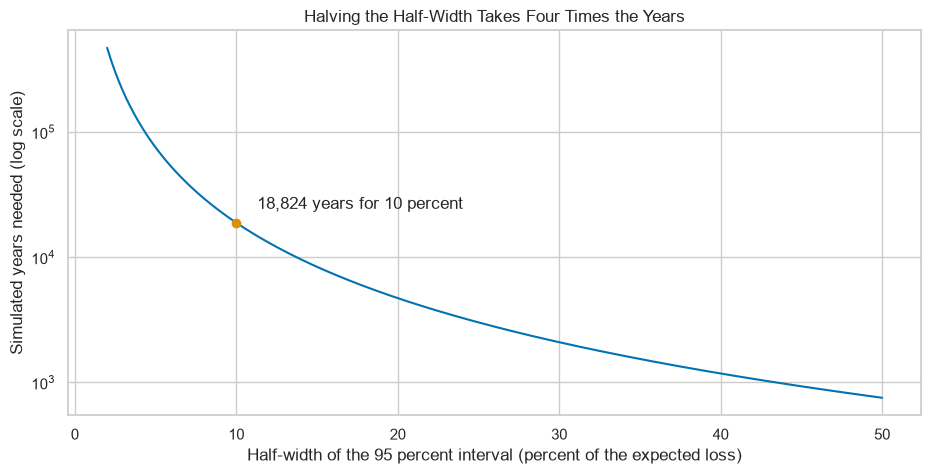

In [41]:
# the years needed at every half-width from 2 to 50 percent of the expected loss, 10 percent marked
share = np.linspace(0.02, 0.5, 200)
needed_10 = math.ceil((1.96 * sd / (0.10 * EL)) ** 2)
plt.figure(figsize=(11, 5))
plt.plot(share * 100, (1.96 * sd / (share * EL)) ** 2, color="C0")
plt.scatter(10, needed_10, color="C1", zorder=3)
plt.annotate(f"{needed_10:,} years for 10 percent", (10, needed_10), xytext=(15, 10), textcoords="offset points")
plt.yscale("log")
plt.xlabel("Half-width of the 95 percent interval (percent of the expected loss)")
plt.ylabel("Simulated years needed (log scale)")
plt.title("Halving the Half-Width Takes Four Times the Years")
plt.show()

## Your Turn: A Rarer Default

Divide sd by EL and LGD and EAD cancel: the years needed for 10 percent depend on PD alone, through sqrt((1 - PD) / PD).

In [42]:
# the years needed for a 95 percent interval within 10 percent of the expected loss, at any PD
def years_needed(chance):
    return math.ceil((1.96 * np.sqrt((1 - chance) / chance) / 0.10) ** 2)

# four PDs as bars, your PD in orange
def draw_years(chance=0.02):
    labels = ["10%", "2%", "0.5%", "0.1%", f"yours, {chance:.1%}"]
    plt.bar(labels, [years_needed(c) for c in [0.10, 0.02, 0.005, 0.001, chance]], color=["C0"] * 4 + ["C1"])
    plt.yscale("log")
    plt.xlabel("PD")
    plt.ylabel("Simulated years needed (log scale)")
    plt.title(f"At a PD of {chance:.1%}, a 10 Percent Answer Takes {years_needed(chance):,} Years")
    plt.show()

In [43]:
# your turn: move the PD and watch the years a 10 percent answer takes
interact(draw_years, chance=(0.001, 0.10, 0.001));

interactive(children=(FloatSlider(value=0.02, description='chance', max=0.1, min=0.001, step=0.001), Output())…

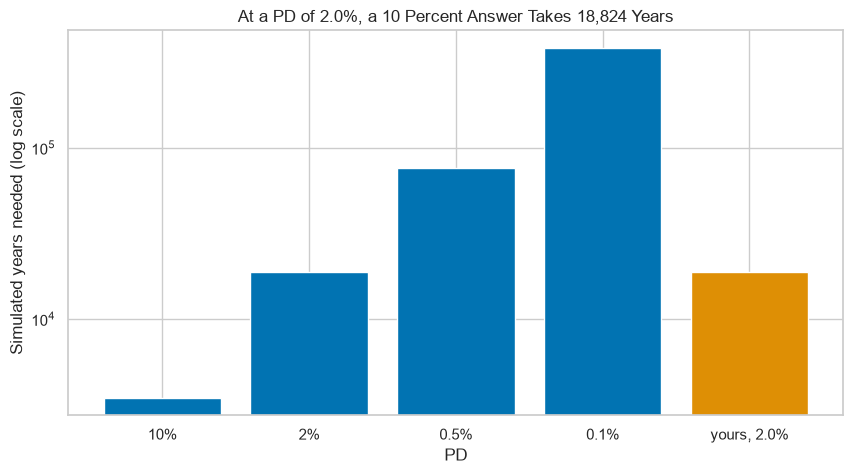

In [44]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_years(chance=0.02)

In [45]:
# the years needed at four PDs
print([years_needed(c) for c in [0.10, 0.02, 0.005, 0.001]])

[3458, 18824, 76448, 383776]


At a PD of 10 percent 3,458 years give a 10 percent answer; at 0.1 percent it takes 383,776.

**The rarer the loss, the more trials it costs to pin down.**

**Predict 5**

At 500 simulated years an experiment expects about 10 defaults.

Q. In 2,000 experiments of 500 years each, in what percent does the 95 percent interval hold the exact expected loss? Write down a number.

## Checking the 95 Percent Interval

In [46]:
# 2,000 experiments at each size, each size from its own child of SEED: mean and standard error (se) in US$
results = []
for years, child in zip([500, 5_000], np.random.default_rng(SEED).spawn(2)):
    for experiment in range(2_000):
        sample = np.where(child.random(years) < PD, LGD * EAD, 0.0)
        results.append({"years": years, "mean": sample.mean(), "se": sample.std(ddof=1) / np.sqrt(years)})
experiments = pd.DataFrame(results)

In [47]:
# the share of experiments whose interval, mean plus or minus 1.96 standard errors, holds EL
experiments["holds"] = (experiments["mean"] - 1.96 * experiments["se"] <= EL) & (EL <= experiments["mean"] + 1.96 * experiments["se"])
experiments.groupby("years")["holds"].mean()

years
500     0.9210
5000    0.9545
Name: holds, dtype: float64

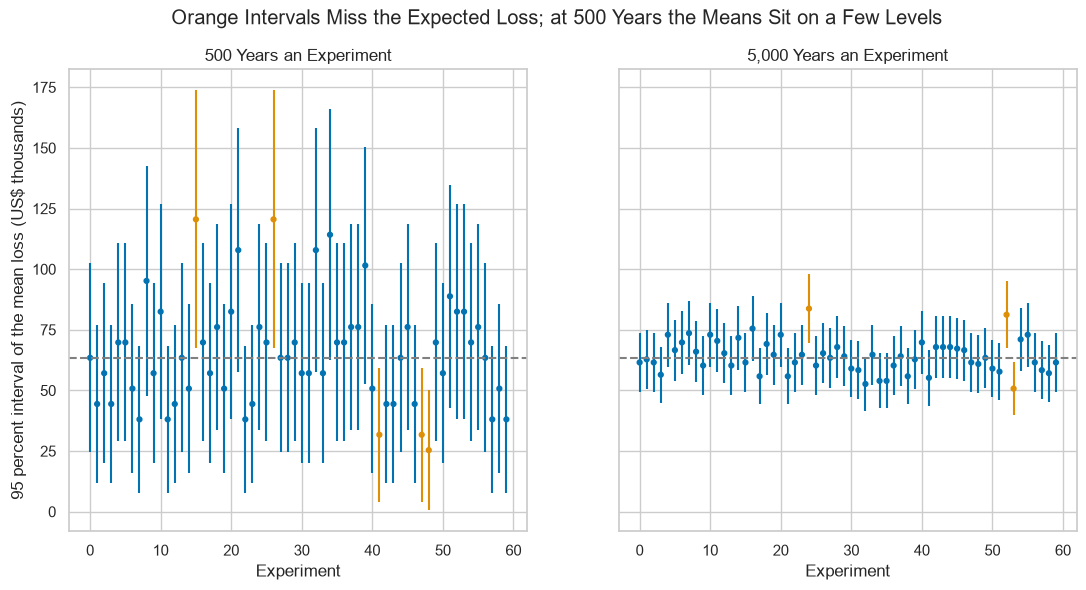

In [48]:
# the first 60 intervals at each size, the misses in orange, EL dashed
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, years in zip(axes, [500, 5_000]):
    first60 = experiments[experiments["years"] == years].head(60)
    colours = np.where(first60["holds"], "C0", "C1")
    ax.vlines(range(60), (first60["mean"] - 1.96 * first60["se"]) / 1e3, (first60["mean"] + 1.96 * first60["se"]) / 1e3, colors=colours)
    ax.scatter(range(60), first60["mean"] / 1e3, c=colours, s=12)
    ax.axhline(EL / 1e3, color="gray", linestyle="--")
    ax.set(title=f"{years:,} Years an Experiment", xlabel="Experiment")
axes[0].set_ylabel("95 percent interval of the mean loss (US$ thousands)")
fig.suptitle("Orange Intervals Miss the Expected Loss; at 500 Years the Means Sit on a Few Levels")
plt.show()

In [49]:
# the misses at 500 years: how many, how many fell short of EL, and how many values the means take
small = experiments[experiments["years"] == 500]
misses = small[~small["holds"]]
print("Misses:", len(misses), "| short of EL:", (misses["mean"] < EL).sum(), "| distinct means:", small["mean"].nunique())

Misses: 158 | short of EL: 140 | distinct means: 23


At 500 years the interval held the exact answer 92.1 percent of the time; at 5,000 years, 95.45 percent.

140 of the 158 misses fall short: an experiment with few defaults has a low mean and a narrow interval at once.

The 500-year means take only 23 values, one step for each default more or less.

**With about ten expected defaults, a Monte Carlo interval claims more precision than it has.**

# Insights and Conclusion

100,000 simulated years landed within US$286 of PD x LGD x EAD, with a standard error of US$1,401.

A hundred times the trials bought ten times the precision.

A loss with a 2 percent chance has a standard deviation seven times its mean, so a 10 percent answer took 18,824 years.

One seed, spawned children for experiments side by side, and never numpy's global state.

At the same standard deviation, a t with 3 degrees of freedom put about five times the normal's share beyond 3.

Independent defaults landed on the binomial.

Antithetic pairs saved 7.3 times on a monotone payoff and cost on a symmetric one.

At 500 years the 95 percent interval held only 92.1 percent of the time.

**A Monte Carlo number without its standard error is half an answer.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Simulate one bond's credit loss year by year and set it beside PD x LGD x EAD.
* Report a simulated mean with its standard error.
* Seed a generator and split it into independent streams with `spawn`.
* Turn uniform draws into normal ones, and draw normal, Student's t, lognormal and beta inputs.
* Check a simulated count against the binomial, and measure what antithetic pairs save.
* Work out the trials a stated precision needs, and test an interval's coverage.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [50]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Three or More Defaults**

Q. Store the exact chance that three or more of the fifty independent bonds default in a year in `ex1_at_least_3`, and the share of the 100,000 simulated years in `counts` with three or more in `ex1_simulated`.

In [51]:
# three or more is more than 2, so the binomial's sf at 2; the simulated share from the same counts
ex1_at_least_3 = stats.binom.sf(2, 50, PD)
ex1_simulated = np.mean(counts >= 3)
print(ex1_at_least_3, ex1_simulated)

0.0784277483509691 0.07727


The simulation lands within about one tenth of a percentage point of the exact chance.

In [52]:
check("Exercise 1 the exact chance of 3 or more", ex1_at_least_3, 0.0784277483509691)
check("Exercise 1 the simulated share of 3 or more", ex1_simulated, 0.07727)

Exercise 1 the exact chance of 3 or more: correct
Exercise 1 the simulated share of 3 or more: correct


### Exercise 2

**A Function for the Trials**

At confidence c the interval runs `stats.norm.ppf(0.5 + c / 2)` standard errors either side, 1.96 at 95 percent.

Q. Write `trials_needed(sd, half_width, confidence)`, which returns the trials needed, rounded up, and store the years needed for within 5 percent of today's expected loss at 99 percent in `ex2_trials`.

In [53]:
# the trials for a stated precision at any confidence
def trials_needed(sd, half_width, confidence):
    """The trials needed for an interval of half_width at this confidence, rounded up."""
    z_value = stats.norm.ppf(0.5 + confidence / 2)
    return math.ceil((z_value * sd / half_width) ** 2)

# within 5 percent at 99 percent, and the lesson's 10 percent at 95 percent as a check
ex2_trials = trials_needed(sd, 0.05 * EL, 0.99)
print(ex2_trials, trials_needed(sd, 0.10 * EL, 0.95))

130044 18824


At 99 percent a 5 percent answer takes about seven times the 18,824 years a 10 percent answer takes at 95 percent.

In [54]:
check("Exercise 2 the years for 5 percent at 99 percent", ex2_trials, 130044)

Exercise 2 the years for 5 percent at 99 percent: correct


### Exercise 3

**An Uncertain LGD**

The LGD is now a draw, `rng_lgd.beta(6, 4, 100_000)`, an input with mean 0.60 chosen for this exercise.

Q. With `rng_default, rng_lgd = np.random.default_rng(SEED).spawn(2)`, simulate 100,000 years of today's bond, defaulting below PD on `rng_default.random(100_000)`, and store the standard error of the mean loss in US$ in `ex3_se`.

In [55]:
# one child for whether the bond defaults, one for how much it loses
rng_default, rng_lgd = np.random.default_rng(SEED).spawn(2)
defaulted = rng_default.random(100_000) < PD
lgd_draws = rng_lgd.beta(6, 4, 100_000)
beta_losses = np.where(defaulted, lgd_draws * EAD, 0.0)
ex3_se = beta_losses.std(ddof=1) / np.sqrt(100_000)
print("Mean (US$):", round(beta_losses.mean(), 2), "| standard error (US$):", ex3_se)

Mean (US$): 61822.57 | standard error (US$): 1423.2217655796428


The standard error barely moves from the fixed LGD's US$1,401.42: whether the bond defaults matters far more than how much it loses.

In [56]:
check("Exercise 3 the standard error with a beta LGD", ex3_se, 1423.2217655796428)

Exercise 3 the standard error with a beta LGD: correct


### Exercise 4: AI check

**Years That Never Default**

You asked an AI assistant for a function that simulates one bond's yearly losses from a generator you pass.
This came back.
Test it against the exact expected loss, then find the one bug.

In [57]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def simulate_losses(rng, n, chance, lgd, ead):
    """n simulated years of one bond's loss in US$, drawn from rng; their mean lands near chance x lgd x ead."""
    year_losses = np.zeros(n)
    for year in range(n):
        draw = np.random.default_rng(42).random()
        if draw < chance:
            year_losses[year] = lgd * ead
    return year_losses

In [58]:
# the docstring's promise on 1,000 years, against the exact expected loss
test = simulate_losses(np.random.default_rng(SEED), 1_000, PD, LGD, EAD)
print("Mean (US$):", test.mean(), "| exact (US$):", round(EL, 2), "| distinct losses:", len(np.unique(test)))

Mean (US$): 0.0 | exact (US$): 63449.55 | distinct losses: 1


Q. Fix the one wrong line, and store the fixed function's mean loss over 20,000 years from `np.random.default_rng(SEED)` in `ex4_mean`.

In [59]:
# the fix: draw from the generator passed in, once a year, never from a fresh generator made inside the loop
def simulate_losses(rng, n, chance, lgd, ead):
    """n simulated years of one bond's loss in US$, drawn from rng; their mean lands near chance x lgd x ead."""
    year_losses = np.zeros(n)
    for year in range(n):
        draw = rng.random()
        if draw < chance:
            year_losses[year] = lgd * ead
    return year_losses

ex4_mean = simulate_losses(np.random.default_rng(SEED), 20_000, PD, LGD, EAD).mean()
print(ex4_mean)

63608.173875


A generator made from 42 inside the loop starts over every year, so every year draws the same first number, 0.774, and none falls below 0.02.

The function ignored the generator it was given; the fixed one uses it and lands near the expected loss.

In [60]:
check("Exercise 4 the fixed mean over 20,000 years", ex4_mean, 63608.173875)

Exercise 4 the fixed mean over 20,000 years: correct


## Congratulations!

You simulated a bond's credit loss year by year and watched 100,000 years land on PD x LGD x EAD.
You learned to say how far a simulated mean can be off, and how many trials a precision costs.
You seeded generators the way a risk team can rerun and audit, drew five kinds of risk input, and checked a simulation against the binomial.
You also caught a 95 percent interval that holds less than 95 percent, which keeps every later number honest.
In Day 2 you turn the book's own daily moves into a loss distribution and read its VaR.

[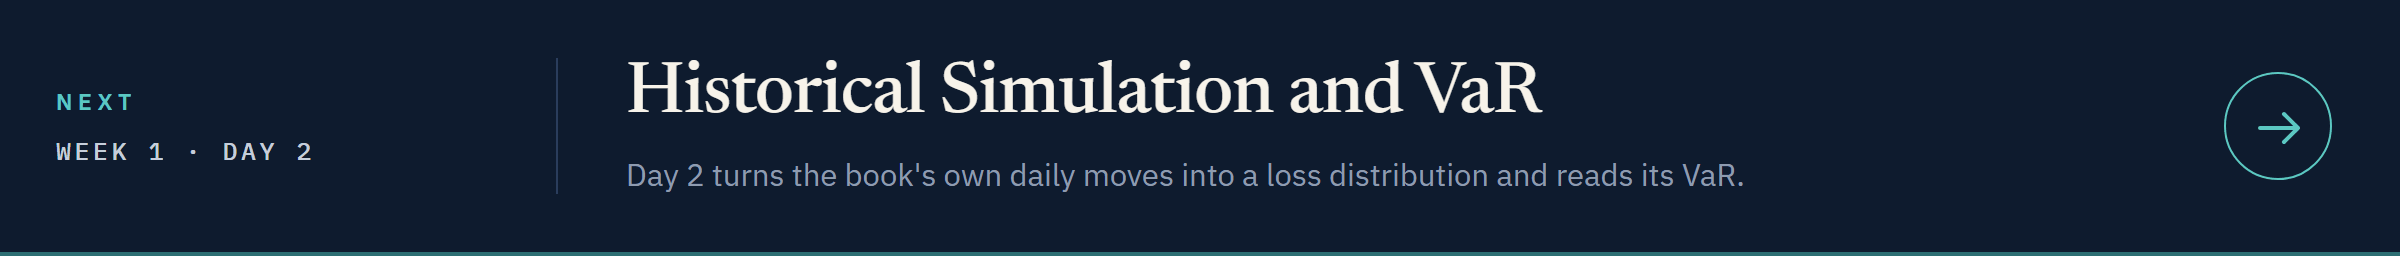](../day2/02_historical_simulation_and_var.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day2/02_historical_simulation_and_var.ipynb)